# Keras z TensorFlow (deeplizard) — Wideo 1–21

Kod według kursu *TensorFlow - Python Deep Learning Neural Network API* (deeplizard).
Uruchamiać od góry do dołu: **Środowisko wykonawcze → Uruchom wszystko**.

## Wideo 1: Wprowadzenie i wymagania wstępne

Wideo wprowadzające — bez kodu.

## Wideo 2: Obsługa GPU w TensorFlow i Keras

In [212]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import categorical_crossentropy

import numpy as np
from random import randint
from sklearn.utils import shuffle
from sklearn.preprocessing import MinMaxScaler

In [213]:
# Sprawdzamy, czy TensorFlow widzi GPU, i włączamy stopniowe przydzielanie pamięci GPU
physical_devices = tf.config.experimental.list_physical_devices('GPU')
print("Num GPUs Available: ", len(physical_devices))
tf.config.experimental.set_memory_growth(physical_devices[0], True)

Num GPUs Available:  1


## Wideo 3: Przetwarzanie danych do trenowania sieci neuronowej

In [214]:
train_labels = []
train_samples = []

In [215]:
for i in range(50):
    # ~5% młodszych osób, które doświadczyły skutków ubocznych
    random_younger = randint(13,64)
    train_samples.append(random_younger)
    train_labels.append(1)

    # ~5% starszych osób, które nie doświadczyły skutków ubocznych
    random_older = randint(65,100)
    train_samples.append(random_older)
    train_labels.append(0)

for i in range(1000):
    # ~95% młodszych osób, które nie doświadczyły skutków ubocznych
    random_younger = randint(13,64)
    train_samples.append(random_younger)
    train_labels.append(0)

    # ~95% starszych osób, które doświadczyły skutków ubocznych
    random_older = randint(65,100)
    train_samples.append(random_older)
    train_labels.append(1)

In [216]:
for i in train_samples:
    print(i)

29
82
38
67
31
77
51
95
39
75
48
90
41
68
44
68
46
86
28
96
23
93
48
66
16
78
34
68
16
86
62
77
61
94
33
91
17
77
54
79
31
74
19
79
34
80
32
73
61
69
34
68
44
70
21
91
16
84
34
77
19
98
59
82
14
94
33
100
50
84
41
95
14
96
62
77
29
84
47
94
17
74
16
93
34
97
52
67
14
100
36
92
51
69
35
66
42
86
34
71
15
73
40
77
24
72
61
78
52
98
56
70
13
87
42
78
15
86
63
75
45
98
29
85
56
95
40
98
27
65
34
66
19
79
44
76
42
73
16
88
56
97
58
92
54
87
27
72
35
82
34
76
58
85
20
82
58
76
21
79
24
76
59
73
59
91
43
89
53
92
28
88
15
83
21
78
20
99
23
99
25
75
18
69
28
91
18
78
63
96
24
92
15
73
47
77
51
77
38
76
54
75
24
69
49
71
22
84
20
65
54
68
25
79
18
70
24
80
33
90
56
86
35
94
18
92
48
73
45
73
57
68
19
82
16
87
40
79
15
88
49
83
41
98
34
87
21
68
13
68
61
90
19
74
13
98
29
93
34
84
60
70
47
68
64
74
54
99
54
94
38
77
29
98
27
68
42
98
54
99
58
91
62
86
62
76
50
79
64
65
42
80
37
83
42
100
33
72
64
67
62
85
32
98
15
66
34
74
18
78
20
96
59
75
21
69
50
68
60
92
57
98
60
91
43
83
17
100
53
82
64
100

In [217]:
for i in train_labels:
    print(i)

1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1
0
1


In [218]:
train_labels = np.array(train_labels)
train_samples = np.array(train_samples)
train_labels, train_samples = shuffle(train_labels, train_samples)

In [219]:
scaler = MinMaxScaler(feature_range=(0,1))
scaled_train_samples = scaler.fit_transform(train_samples.reshape(-1,1))

In [220]:
for i in scaled_train_samples:
    print(i)

[0.50574713]
[0.40229885]
[0.47126437]
[0.70114943]
[0.59770115]
[0.11494253]
[0.71264368]
[0.37931034]
[0.54022989]
[0.36781609]
[0.97701149]
[0.1954023]
[0.94252874]
[0.59770115]
[0.42528736]
[1.]
[0.47126437]
[0.33333333]
[0.43678161]
[0.2183908]
[0.35632184]
[0.8045977]
[0.55172414]
[0.64367816]
[0.97701149]
[0.91954023]
[0.8045977]
[0.34482759]
[0.06896552]
[0.48275862]
[0.64367816]
[0.89655172]
[0.81609195]
[0.3908046]
[0.7816092]
[0.33333333]
[0.88505747]
[0.27586207]
[0.3908046]
[0.62068966]
[0.54022989]
[0.83908046]
[0.36781609]
[0.17241379]
[0.34482759]
[0.64367816]
[0.73563218]
[0.89655172]
[0.75862069]
[0.63218391]
[0.29885057]
[0.01149425]
[0.93103448]
[1.]
[0.89655172]
[0.62068966]
[0.31034483]
[0.01149425]
[0.31034483]
[0.97701149]
[0.35632184]
[0.96551724]
[0.13793103]
[0.71264368]
[0.05747126]
[0.57471264]
[0.54022989]
[0.14942529]
[0.89655172]
[0.03448276]
[0.]
[0.25287356]
[0.62068966]
[0.88505747]
[0.77011494]
[0.91954023]
[0.94252874]
[0.64367816]
[0.65517241]
[0.7

## Wideo 4: Tworzenie sztucznej sieci neuronowej

In [221]:
model = Sequential([
    Dense(units=16, input_shape=(1,), activation='relu'),
    Dense(units=32, activation='relu'),
    Dense(units=2, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [222]:
model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_17 (Dense)                │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 642 (2.51 KB)

 Trainable params: 642 (2.51 KB)

 Non-trainable params: 0 (0.00 B)

## Wideo 5: Trenowanie sztucznej sieci neuronowej

In [223]:
model.compile(optimizer=Adam(learning_rate=0.0001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [224]:
model.fit(x=scaled_train_samples, y=train_labels, batch_size=10, epochs=30, shuffle=True, verbose=2)

Epoch 1/30
210/210 - 2s - 8ms/step - accuracy: 0.4581 - loss: 0.7236
Epoch 2/30
210/210 - 0s - 2ms/step - accuracy: 0.4471 - loss: 0.6966
Epoch 3/30
210/210 - 0s - 2ms/step - accuracy: 0.5776 - loss: 0.6728
Epoch 4/30
210/210 - 0s - 2ms/step - accuracy: 0.6686 - loss: 0.6468
Epoch 5/30
210/210 - 0s - 2ms/step - accuracy: 0.7438 - loss: 0.6118
Epoch 6/30
210/210 - 0s - 2ms/step - accuracy: 0.7900 - loss: 0.5797
Epoch 7/30
210/210 - 0s - 2ms/step - accuracy: 0.8057 - loss: 0.5472
Epoch 8/30
210/210 - 0s - 2ms/step - accuracy: 0.8338 - loss: 0.5160
Epoch 9/30
210/210 - 0s - 2ms/step - accuracy: 0.8595 - loss: 0.4864
Epoch 10/30
210/210 - 0s - 2ms/step - accuracy: 0.8667 - loss: 0.4587
Epoch 11/30
210/210 - 0s - 2ms/step - accuracy: 0.8824 - loss: 0.4329
Epoch 12/30
210/210 - 0s - 2ms/step - accuracy: 0.8895 - loss: 0.4098
Epoch 13/30
210/210 - 0s - 2ms/step - accuracy: 0.8981 - loss: 0.3894
Epoch 14/30
210/210 - 0s - 2ms/step - accuracy: 0.9024 - loss: 0.3718
Epoch 15/30
210/210 - 0s - 2m

## Wideo 6: Zbiór walidacyjny

In [225]:
# validation_split=0.1 — 10% danych treningowych trafia do zbioru walidacyjnego
model.fit(x=scaled_train_samples, y=train_labels, validation_split=0.1, batch_size=10, epochs=30, shuffle=True, verbose=2)

Epoch 1/30
189/189 - 1s - 5ms/step - accuracy: 0.9370 - loss: 0.2754 - val_accuracy: 0.9429 - val_loss: 0.2537
Epoch 2/30
189/189 - 0s - 3ms/step - accuracy: 0.9370 - loss: 0.2741 - val_accuracy: 0.9429 - val_loss: 0.2525
Epoch 3/30
189/189 - 0s - 3ms/step - accuracy: 0.9370 - loss: 0.2728 - val_accuracy: 0.9429 - val_loss: 0.2508
Epoch 4/30
189/189 - 0s - 3ms/step - accuracy: 0.9370 - loss: 0.2716 - val_accuracy: 0.9429 - val_loss: 0.2494
Epoch 5/30
189/189 - 0s - 3ms/step - accuracy: 0.9370 - loss: 0.2704 - val_accuracy: 0.9429 - val_loss: 0.2482
Epoch 6/30
189/189 - 0s - 3ms/step - accuracy: 0.9370 - loss: 0.2693 - val_accuracy: 0.9429 - val_loss: 0.2469
Epoch 7/30
189/189 - 0s - 2ms/step - accuracy: 0.9370 - loss: 0.2684 - val_accuracy: 0.9429 - val_loss: 0.2461
Epoch 8/30
189/189 - 0s - 3ms/step - accuracy: 0.9370 - loss: 0.2675 - val_accuracy: 0.9429 - val_loss: 0.2450
Epoch 9/30
189/189 - 0s - 3ms/step - accuracy: 0.9376 - loss: 0.2666 - val_accuracy: 0.9429 - val_loss: 0.2438
E

## Wideo 7: Predykcje sieci neuronowej

In [226]:
test_labels = []
test_samples = []

for i in range(10):
    # ~5% młodszych osób, które doświadczyły skutków ubocznych
    random_younger = randint(13,64)
    test_samples.append(random_younger)
    test_labels.append(1)

    # ~5% starszych osób, które nie doświadczyły skutków ubocznych
    random_older = randint(65,100)
    test_samples.append(random_older)
    test_labels.append(0)

for i in range(200):
    # ~95% młodszych osób, które nie doświadczyły skutków ubocznych
    random_younger = randint(13,64)
    test_samples.append(random_younger)
    test_labels.append(0)

    # ~95% starszych osób, które doświadczyły skutków ubocznych
    random_older = randint(65,100)
    test_samples.append(random_older)
    test_labels.append(1)

In [227]:
test_labels = np.array(test_labels)
test_samples = np.array(test_samples)
test_labels, test_samples = shuffle(test_labels, test_samples)

scaled_test_samples = scaler.fit_transform(test_samples.reshape(-1,1))

In [228]:
predictions = model.predict(x=scaled_test_samples, batch_size=10, verbose=0)

In [229]:
for i in predictions:
    print(i)

[0.9696966  0.03030341]
[0.04124302 0.95875704]
[0.9589382  0.04106185]
[0.01787039 0.9821297 ]
[0.9696194  0.03038063]
[0.16438746 0.83561254]
[0.96959996 0.03039995]
[0.14156891 0.85843116]
[0.32733384 0.6726662 ]
[0.05158823 0.94841176]
[0.9696966  0.03030341]
[0.36838883 0.6316111 ]
[0.96749306 0.03250694]
[0.96749306 0.03250694]
[0.9696772  0.03032271]
[0.05158823 0.94841176]
[0.9699079  0.03009209]
[0.9136476  0.08635236]
[0.89824504 0.10175499]
[0.07444081 0.9255592 ]
[0.06435423 0.93564576]
[0.9669726  0.03302739]
[0.96971583 0.03028415]
[0.09907787 0.9009222 ]
[0.5010668  0.49893314]
[0.01929627 0.9807037 ]
[0.08596308 0.9140369 ]
[0.969812   0.03018796]
[0.16438746 0.83561254]
[0.12412793 0.8758721 ]
[0.04124302 0.95875704]
[0.95610064 0.04389933]
[0.19080238 0.80919766]
[0.08001277 0.9199872 ]
[0.943251  0.0567489]
[0.9696966  0.03030341]
[0.08596308 0.9140369 ]
[0.02619922 0.9738008 ]
[0.9589382  0.04106185]
[0.9696966  0.03030341]
[0.96977353 0.03022641]
[0.9690073  0.0309

In [230]:
rounded_predictions = np.argmax(predictions, axis=-1)

In [231]:
for i in rounded_predictions:
    print(i)

0
1
0
1
0
1
0
1
1
1
0
1
0
0
0
1
0
0
0
1
1
0
0
1
0
1
1
0
1
1
1
0
1
1
0
0
1
1
0
0
0
0
0
0
1
1
1
1
1
1
1
0
1
1
0
0
0
0
0
0
0
1
1
1
1
1
1
0
1
1
1
1
1
1
1
1
0
1
0
0
1
0
1
0
0
0
1
0
0
0
0
1
0
1
0
0
0
1
1
0
0
1
0
1
1
0
1
0
1
0
1
0
1
0
1
0
1
1
1
0
0
1
1
0
1
0
1
1
0
1
0
1
1
1
1
1
1
1
1
0
0
0
0
0
1
0
1
0
0
1
0
1
1
0
0
0
1
1
0
1
1
0
1
0
0
0
0
1
0
1
0
0
0
1
0
1
1
0
0
1
0
0
0
1
1
0
0
1
1
0
0
1
1
1
1
1
1
1
1
1
0
1
1
1
1
0
0
1
1
0
1
0
0
1
1
1
0
1
0
0
1
0
1
0
1
1
1
1
0
0
0
1
1
0
1
0
1
0
1
0
1
0
1
1
0
1
0
0
0
1
1
1
1
1
0
0
1
0
1
0
0
0
1
1
1
0
1
1
1
0
0
0
0
0
0
1
1
0
1
0
0
0
0
0
0
0
0
1
0
1
1
0
0
0
1
0
0
0
1
0
1
0
1
0
1
0
1
0
1
1
0
0
0
0
0
1
1
0
0
0
0
1
1
0
1
1
0
1
1
0
1
0
1
1
1
0
1
1
1
1
0
1
0
1
1
1
0
1
0
1
1
0
1
0
0
1
1
1
0
0
1
0
1
1
0
0
1
1
0
1
1
1
0
0
0
1
0
0
0
0
1
0
0
1
1
1
1
0
1
1
0
0
0
1
1
1
1
1
0
0
1
0
0
0
0
0
0
1
1
0
0
1
1
0
0
1
1
0
1
0


## Wideo 8: Macierz pomyłek (Confusion Matrix)

In [232]:
%matplotlib inline
from sklearn.metrics import confusion_matrix
import itertools
import matplotlib.pyplot as plt

In [233]:
cm = confusion_matrix(y_true=test_labels, y_pred=rounded_predictions)

In [234]:
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    Funkcja wypisuje i rysuje macierz pomyłek.
    Normalizację można włączyć, ustawiając `normalize=True`.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
            horizontalalignment="center",
            color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

Confusion matrix, without normalization
[[197  13]
 [  9 201]]


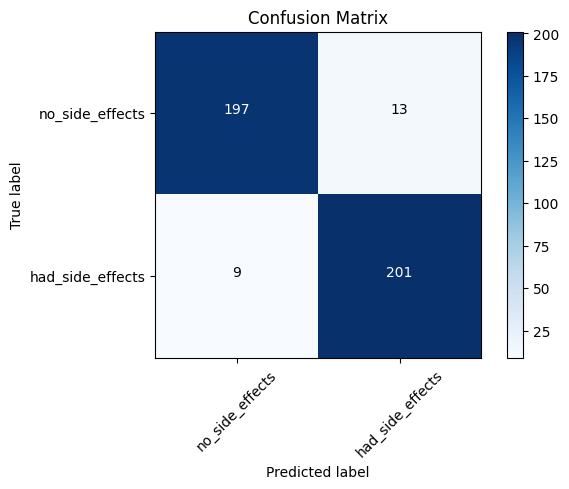

In [235]:
cm_plot_labels = ['no_side_effects','had_side_effects']
plot_confusion_matrix(cm=cm, classes=cm_plot_labels, title='Confusion Matrix')

## Wideo 9: Zapisywanie i wczytywanie modelu

### 1. model.save()

In [236]:
# Folder models/ musi istnieć (w Colab tworzymy go sami)
import os
os.makedirs('models', exist_ok=True)

In [237]:
# Zapisuje architekturę, wagi, konfigurację treningu i stan optymalizatora
import os.path
if os.path.isfile('models/medical_trial_model.h5') is False:
    model.save('models/medical_trial_model.h5')

In [238]:
from tensorflow.keras.models import load_model
new_model = load_model('models/medical_trial_model.h5')

In [239]:
new_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 644 (2.52 KB)

 Trainable params: 642 (2.51 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

In [240]:
new_model.get_weights()

[array([[-0.09346586, -0.13228515, -0.2712492 ,  0.5678689 ,  0.45874348,
         -0.16276109,  0.48505798, -0.25193846,  0.6330141 , -0.4985941 ,
          0.44933838,  0.34265396, -0.24060756, -0.2262016 ,  0.74274826,
         -0.05987197]], dtype=float32),
 array([ 0.        ,  0.23718357,  0.        , -0.1963342 , -0.1782175 ,
         0.        ,  0.10387686,  0.        , -0.16482967,  0.        ,
        -0.16869642, -0.15663229,  0.        ,  0.        , -0.18553762,
         0.        ], dtype=float32),
 array([[-9.80213583e-02,  3.38911921e-01, -2.19664901e-01,
         -1.81638420e-01, -2.23197237e-01,  3.36297482e-01,
         -2.38138378e-01,  8.43717456e-02, -2.31155902e-01,
          3.00769180e-01, -9.16525424e-02, -2.45844156e-01,
         -2.41587922e-01, -1.68541446e-01,  8.45231414e-02,
         -3.40831697e-01,  1.64351761e-02, -1.87536106e-01,
          1.99170977e-01, -3.45205963e-01,  1.47777289e-01,
         -2.31524602e-01, -2.17060819e-01, -2.65983939e-01,
 

In [241]:
new_model.optimizer

### 2. model.to_json()

In [242]:
# Zapisuje tylko architekturę modelu (bez wag i konfiguracji treningu)
json_string = model.to_json()

In [243]:
json_string

'{"module": "keras", "class_name": "Sequential", "config": {"name": "sequential_8", "trainable": true, "dtype": {"module": "keras", "class_name": "DTypePolicy", "config": {"name": "float32"}, "registered_name": null}, "layers": [{"module": "keras.layers", "class_name": "InputLayer", "config": {"batch_shape": [null, 1], "dtype": "float32", "sparse": false, "ragged": false, "name": "input_layer_12", "optional": false}, "registered_name": null}, {"module": "keras.layers", "class_name": "Dense", "config": {"name": "dense_17", "trainable": true, "dtype": {"module": "keras", "class_name": "DTypePolicy", "config": {"name": "float32"}, "registered_name": null}, "units": 16, "activation": "relu", "use_bias": true, "kernel_initializer": {"module": "keras.initializers", "class_name": "GlorotUniform", "config": {"seed": null}, "registered_name": null}, "bias_initializer": {"module": "keras.initializers", "class_name": "Zeros", "config": {}, "registered_name": null}, "kernel_regularizer": null, "bi

In [244]:
# Odtworzenie modelu z JSON
from tensorflow.keras.models import model_from_json
model_architecture = model_from_json(json_string)

In [245]:
model_architecture.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_17 (Dense)                │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,928 (7.54 KB)

 Trainable params: 642 (2.51 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,286 (5.03 KB)

### 3. model.save_weights()

In [246]:
# Zapisuje tylko wagi modelu
import os.path
if os.path.isfile('models/my_model_weights.weights.h5') is False:
    model.save_weights('models/my_model_weights.weights.h5')

In [247]:
model2 = Sequential([
    Dense(units=16, input_shape=(1,), activation='relu'),
    Dense(units=32, activation='relu'),
    Dense(units=2, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [248]:
model2.load_weights('models/my_model_weights.weights.h5')

In [249]:
model2.get_weights()

[array([[-0.09346586, -0.13228515, -0.2712492 ,  0.5678689 ,  0.45874348,
         -0.16276109,  0.48505798, -0.25193846,  0.6330141 , -0.4985941 ,
          0.44933838,  0.34265396, -0.24060756, -0.2262016 ,  0.74274826,
         -0.05987197]], dtype=float32),
 array([ 0.        ,  0.23718357,  0.        , -0.1963342 , -0.1782175 ,
         0.        ,  0.10387686,  0.        , -0.16482967,  0.        ,
        -0.16869642, -0.15663229,  0.        ,  0.        , -0.18553762,
         0.        ], dtype=float32),
 array([[-9.80213583e-02,  3.38911921e-01, -2.19664901e-01,
         -1.81638420e-01, -2.23197237e-01,  3.36297482e-01,
         -2.38138378e-01,  8.43717456e-02, -2.31155902e-01,
          3.00769180e-01, -9.16525424e-02, -2.45844156e-01,
         -2.41587922e-01, -1.68541446e-01,  8.45231414e-02,
         -3.40831697e-01,  1.64351761e-02, -1.87536106e-01,
          1.99170977e-01, -3.45205963e-01,  1.47777289e-01,
         -2.31524602e-01, -2.17060819e-01, -2.65983939e-01,
 

## Wideo 10: Przygotowanie obrazów dla konwolucyjnej sieci neuronowej (CNN)

In [250]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation, Dense, Flatten, BatchNormalization, Conv2D, MaxPool2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import categorical_crossentropy
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import confusion_matrix
import itertools
import os
import shutil
import random
import glob
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
%matplotlib inline

### Pobranie danych

W filmie dane Dogs vs. Cats są pobierane ręcznie z Kaggle i rozpakowywane do `data/dogs-vs-cats`
(wszystkie pliki `cat.*.jpg` i `dog.*.jpg` w jednym folderze).
Tutaj pobieramy te same zdjęcia z otwartego zbioru Microsoft i ustawiamy je tak samo.

In [251]:
import zipfile, urllib.request

if not os.path.isdir('data/dogs-vs-cats'):
    os.makedirs('data/dogs-vs-cats')
    url = "https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip"
    urllib.request.urlretrieve(url, "petimages.zip")
    with zipfile.ZipFile("petimages.zip") as z:
        z.extractall("data/tmp")

    # Nazwy plików jak w filmie: cat.123.jpg / dog.123.jpg (uszkodzone pliki pomijamy)
    for cls, prefix in [('Cat', 'cat'), ('Dog', 'dog')]:
        for f in glob.glob(f'data/tmp/PetImages/{cls}/*.jpg'):
            with open(f, 'rb') as fh:
                if b'JFIF' not in fh.peek(10):
                    continue
            n = os.path.splitext(os.path.basename(f))[0]
            shutil.move(f, f'data/dogs-vs-cats/{prefix}.{n}.jpg')

    shutil.rmtree('data/tmp')
    os.remove('petimages.zip')

In [252]:
# Podział danych na foldery train, valid, test
os.chdir('data/dogs-vs-cats')
if os.path.isdir('train/dog') is False:
    os.makedirs('train/dog')
    os.makedirs('train/cat')
    os.makedirs('valid/dog')
    os.makedirs('valid/cat')
    os.makedirs('test/dog')
    os.makedirs('test/cat')

    for i in random.sample(glob.glob('cat*'), 500):
        shutil.move(i, 'train/cat')
    for i in random.sample(glob.glob('dog*'), 500):
        shutil.move(i, 'train/dog')
    for i in random.sample(glob.glob('cat*'), 100):
        shutil.move(i, 'valid/cat')
    for i in random.sample(glob.glob('dog*'), 100):
        shutil.move(i, 'valid/dog')
    for i in random.sample(glob.glob('cat*'), 50):
        shutil.move(i, 'test/cat')
    for i in random.sample(glob.glob('dog*'), 50):
        shutil.move(i, 'test/dog')

os.chdir('../../')

In [253]:
# Pamięć GPU została już skonfigurowana w sekcji Wideo 2 (ponowne set_memory_growth w tej samej sesji daje błąd)
physical_devices = tf.config.experimental.list_physical_devices('GPU')
print("Num GPUs Available: ", len(physical_devices))

Num GPUs Available:  1


In [254]:
train_path = 'data/dogs-vs-cats/train'
valid_path = 'data/dogs-vs-cats/valid'
test_path = 'data/dogs-vs-cats/test'

In [255]:
train_batches = ImageDataGenerator(preprocessing_function=tf.keras.applications.vgg16.preprocess_input) \
    .flow_from_directory(directory=train_path, target_size=(224,224), classes=['cat', 'dog'], batch_size=10)
valid_batches = ImageDataGenerator(preprocessing_function=tf.keras.applications.vgg16.preprocess_input) \
    .flow_from_directory(directory=valid_path, target_size=(224,224), classes=['cat', 'dog'], batch_size=10)
test_batches = ImageDataGenerator(preprocessing_function=tf.keras.applications.vgg16.preprocess_input) \
    .flow_from_directory(directory=test_path, target_size=(224,224), classes=['cat', 'dog'], batch_size=10, shuffle=False)

Found 1000 images belonging to 2 classes.
Found 200 images belonging to 2 classes.
Found 100 images belonging to 2 classes.


In [256]:
imgs, labels = next(train_batches)

In [257]:
# Funkcja z dokumentacji TensorFlow — rysuje obrazy w siatce 1 wiersz x 10 kolumn
def plotImages(images_arr):
    fig, axes = plt.subplots(1, 10, figsize=(20,20))
    axes = axes.flatten()
    for img, ax in zip( images_arr, axes):
        ax.imshow(img)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

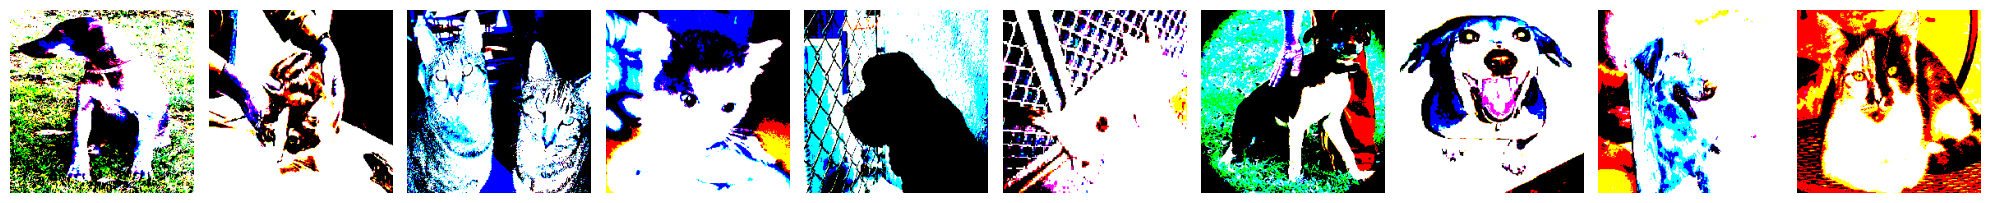

[[0. 1.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [0. 1.]
 [1. 0.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [1. 0.]]


In [258]:
plotImages(imgs)
print(labels)

## Wideo 11: Aktualizacja kodu do trenowania CNN

Wideo bez nowego kodu. Wniosek: gdy dane są w `DirectoryIterator` (z `flow_from_directory()`),
do `fit()` podajemy `steps_per_epoch` i `validation_steps`, a do `predict()` — `steps`.
Zwykle jest to `len(train_batches)`, `len(valid_batches)` i `len(test_batches)`.

## Wideo 12: Budowa i trenowanie konwolucyjnej sieci neuronowej

In [259]:
model = Sequential([
    Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding = 'same', input_shape=(224,224,3)),
    MaxPool2D(pool_size=(2, 2), strides=2),
    Conv2D(filters=64, kernel_size=(3, 3), activation='relu', padding = 'same'),
    MaxPool2D(pool_size=(2, 2), strides=2),
    Flatten(),
    Dense(units=2, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [260]:
model.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 200704)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 2)              │       401,410 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 420,802 (1.61 MB)

 Trainable params: 420,802 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [261]:
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

In [262]:
model.fit(x=train_batches,
    steps_per_epoch=len(train_batches),
    validation_data=valid_batches,
    validation_steps=len(valid_batches),
    epochs=10,
    verbose=2
)

Epoch 1/10
100/100 - 6s - 57ms/step - accuracy: 0.5460 - loss: 17.1228 - val_accuracy: 0.6150 - val_loss: 5.8045
Epoch 2/10
100/100 - 4s - 35ms/step - accuracy: 0.7150 - loss: 3.6472 - val_accuracy: 0.6600 - val_loss: 4.1807
Epoch 3/10
100/100 - 4s - 36ms/step - accuracy: 0.8190 - loss: 1.3895 - val_accuracy: 0.6750 - val_loss: 2.2982
Epoch 4/10
100/100 - 3s - 35ms/step - accuracy: 0.9400 - loss: 0.1810 - val_accuracy: 0.6800 - val_loss: 3.1024
Epoch 5/10
100/100 - 4s - 35ms/step - accuracy: 0.9740 - loss: 0.0788 - val_accuracy: 0.6600 - val_loss: 2.0271
Epoch 6/10
100/100 - 3s - 35ms/step - accuracy: 0.9950 - loss: 0.0154 - val_accuracy: 0.6850 - val_loss: 2.1127
Epoch 7/10
100/100 - 3s - 32ms/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 0.6950 - val_loss: 2.1827
Epoch 8/10
100/100 - 4s - 35ms/step - accuracy: 1.0000 - loss: 5.5714e-04 - val_accuracy: 0.6950 - val_loss: 2.1589
Epoch 9/10
100/100 - 4s - 36ms/step - accuracy: 1.0000 - loss: 4.2495e-04 - val_accuracy: 0.6950 - 

## Wideo 13: Predykcje konwolucyjnej sieci neuronowej

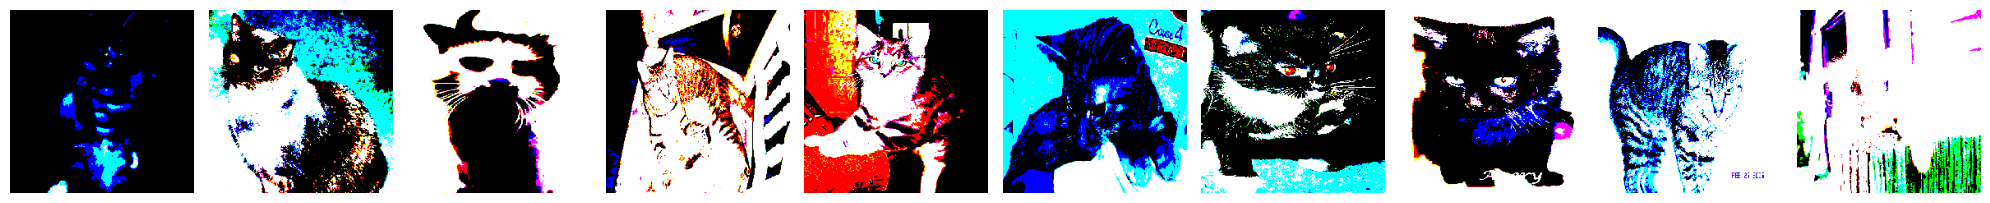

[[1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]]


In [263]:
test_imgs, test_labels = next(test_batches)
plotImages(test_imgs)
print(test_labels)

In [264]:
test_batches.classes

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], dtype=int32)

In [265]:
predictions = model.predict(x=test_batches, steps=len(test_batches), verbose=0)

In [266]:
np.round(predictions)

array([[1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [1., 0.

In [267]:
cm = confusion_matrix(y_true=test_batches.classes, y_pred=np.argmax(predictions, axis=-1))

In [268]:
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    Funkcja wypisuje i rysuje macierz pomyłek.
    Normalizację można włączyć, ustawiając `normalize=True`.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
            horizontalalignment="center",
            color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

In [269]:
test_batches.class_indices

{'cat': 0, 'dog': 1}

Confusion matrix, without normalization
[[29 21]
 [10 40]]


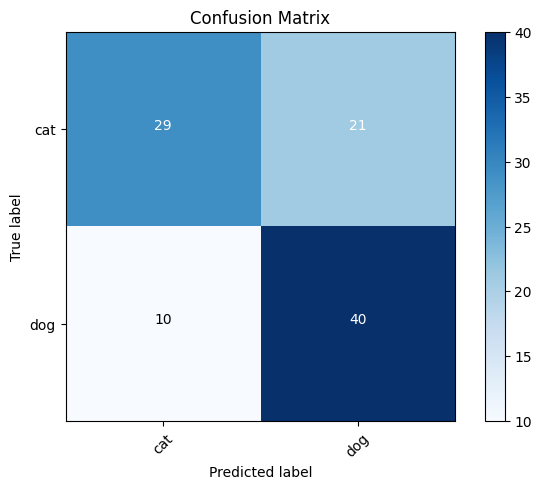

In [270]:
cm_plot_labels = ['cat','dog']
plot_confusion_matrix(cm=cm, classes=cm_plot_labels, title='Confusion Matrix')

## Wideo 14: Augmentacja danych

In [271]:
import matplotlib.pyplot as plt
import numpy as np
import os
import random
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
%matplotlib inline

In [272]:
# Funkcja z dokumentacji TensorFlow — rysuje obrazy w siatce 1 wiersz x 10 kolumn
def plotImages(images_arr):
    fig, axes = plt.subplots(1, 10, figsize=(20,20))
    axes = axes.flatten()
    for img, ax in zip( images_arr, axes):
        ax.imshow(img)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

In [273]:
# Parametry określają sposoby modyfikowania (augmentacji) obrazu
gen = ImageDataGenerator(rotation_range=10, width_shift_range=0.1, height_shift_range=0.1, shear_range=0.15, zoom_range=0.1,
    channel_shift_range=10., horizontal_flip=True)

In [274]:
# Losowe zdjęcie psa ze zbioru treningowego
chosen_image = random.choice(os.listdir('data/dogs-vs-cats/train/dog'))

In [275]:
image_path = 'data/dogs-vs-cats/train/dog/' + chosen_image

In [276]:
image = np.expand_dims(plt.imread(image_path),0)

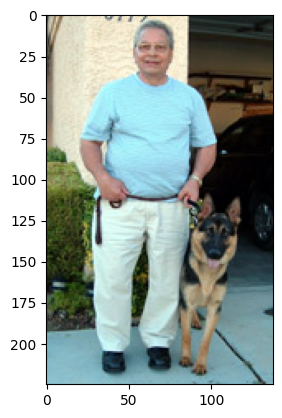

In [277]:
plt.imshow(image[0])

In [278]:
# Generujemy partie zaugmentowanych obrazów z oryginalnego obrazu
aug_iter = gen.flow(image)

In [279]:
aug_images = [next(aug_iter)[0].astype(np.uint8) for i in range(10)]

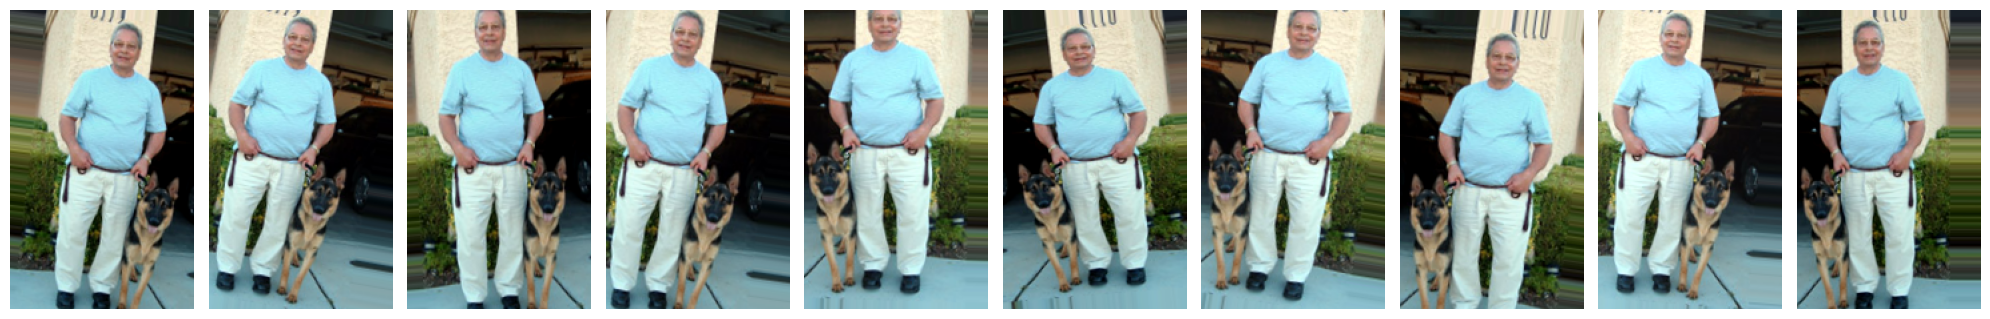

In [280]:
plotImages(aug_images)

In [281]:
# Zapisywanie zaugmentowanych obrazów na dysk (zapis następuje dopiero przy pobieraniu partii z iteratora)
aug_iter = gen.flow(image, save_to_dir='data/dogs-vs-cats/train/dog', save_prefix='aug-image-', save_format='jpeg')

## Wideo 15: Budowa dostrojonej (fine-tuned) sieci neuronowej — VGG16

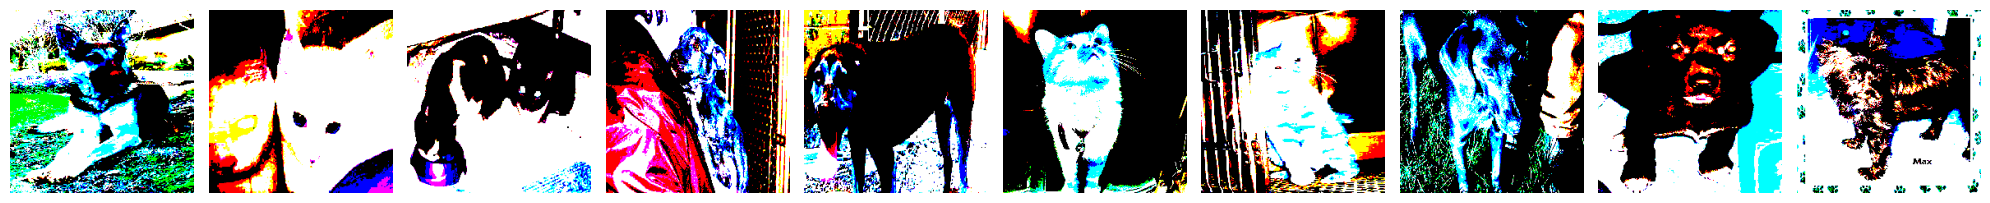

[[0. 1.]
 [1. 0.]
 [1. 0.]
 [0. 1.]
 [0. 1.]
 [1. 0.]
 [1. 0.]
 [0. 1.]
 [0. 1.]
 [0. 1.]]


In [282]:
imgs, labels = next(train_batches)
plotImages(imgs)
print(labels)

In [283]:
# Pobranie modelu VGG16 (wymaga połączenia z internetem)
vgg16_model = tf.keras.applications.vgg16.VGG16()

In [284]:
vgg16_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_15 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1000)           │     4,097,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,357,544 (527.79 MB)

 Trainable params: 138,357,544 (527.79 MB)

 Non-trainable params: 0 (0.00 B)

In [285]:
type(vgg16_model)

keras.src.models.functional.Functional

In [286]:
# Kopiujemy wszystkie warstwy VGG16 oprócz ostatniej do modelu Sequential
model = Sequential()
for layer in vgg16_model.layers[:-1]:
    model.add(layer)

In [287]:
model.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 134,260,544 (512.16 MB)

 Trainable params: 134,260,544 (512.16 MB)

 Non-trainable params: 0 (0.00 B)

In [288]:
# Zamrażamy wagi — te warstwy nie będą trenowane
for layer in model.layers:
    layer.trainable = False

In [289]:
# Nowa warstwa wyjściowa: 2 klasy (kot, pies)
model.add(Dense(units=2, activation='softmax'))

In [290]:
model.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 2)              │         8,194 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 134,268,738 (512.19 MB)

 Trainable params: 8,194 (32.01 KB)

 Non-trainable params: 134,260,544 (512.16 MB)

## Wideo 16: Trenowanie dostrojonej sieci neuronowej

In [291]:
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

In [292]:
model.fit(x=train_batches,
          steps_per_epoch=len(train_batches),
          validation_data=valid_batches,
          validation_steps=len(valid_batches),
          epochs=5,
          verbose=2
)

Epoch 1/5
100/100 - 11s - 111ms/step - accuracy: 0.8640 - loss: 0.3230 - val_accuracy: 0.9600 - val_loss: 0.1209
Epoch 2/5
100/100 - 8s - 82ms/step - accuracy: 0.9770 - loss: 0.0791 - val_accuracy: 0.9750 - val_loss: 0.0801
Epoch 3/5
100/100 - 8s - 82ms/step - accuracy: 0.9880 - loss: 0.0488 - val_accuracy: 0.9650 - val_loss: 0.0733
Epoch 4/5
100/100 - 8s - 83ms/step - accuracy: 0.9910 - loss: 0.0364 - val_accuracy: 0.9850 - val_loss: 0.0548
Epoch 5/5
100/100 - 9s - 86ms/step - accuracy: 0.9940 - loss: 0.0287 - val_accuracy: 0.9850 - val_loss: 0.0500


## Wideo 17: Predykcje dostrojonej sieci neuronowej

In [293]:
predictions = model.predict(x=test_batches, steps=len(test_batches), verbose=0)

In [294]:
test_batches.classes

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], dtype=int32)

In [295]:
cm = confusion_matrix(y_true=test_batches.classes, y_pred=np.argmax(predictions, axis=-1))

In [296]:
test_batches.class_indices

{'cat': 0, 'dog': 1}

Confusion matrix, without normalization
[[50  0]
 [ 3 47]]


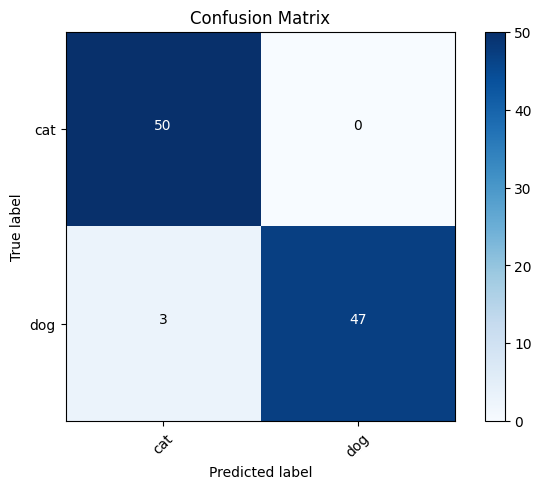

In [297]:
cm_plot_labels = ['cat','dog']
plot_confusion_matrix(cm=cm, classes=cm_plot_labels, title='Confusion Matrix')

## Wideo 18: Klasyfikacja obrazów za pomocą MobileNet
`data/MobileNet-samples`
pod nazwami `1.PNG` (jaszczurka), `2.PNG` (espresso), `3.PNG` (truskawka) —
w Colab: ikona folderu po lewej.

In [298]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense, Activation
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import categorical_crossentropy
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import Model
from tensorflow.keras.applications import imagenet_utils
from sklearn.metrics import confusion_matrix
import itertools
import os
import shutil
import random
import matplotlib.pyplot as plt
%matplotlib inline

In [299]:
# Pamięć GPU została już skonfigurowana w sekcji Wideo 2
physical_devices = tf.config.experimental.list_physical_devices('GPU')
print("Num GPUs Available: ", len(physical_devices))

Num GPUs Available:  1


In [300]:
os.makedirs('data/MobileNet-samples', exist_ok=True)

In [302]:
# Pobranie modelu MobileNet (wymaga połączenia z internetem)
mobile = tf.keras.applications.mobilenet.MobileNet()

In [303]:
# Wczytuje obraz, zmienia rozmiar na 224x224 i wykonuje preprocessing MobileNet
def prepare_image(file):
    img_path = 'data/MobileNet-samples/'
    img = image.load_img(img_path + file, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array_expanded_dims = np.expand_dims(img_array, axis=0)
    return tf.keras.applications.mobilenet.preprocess_input(img_array_expanded_dims)

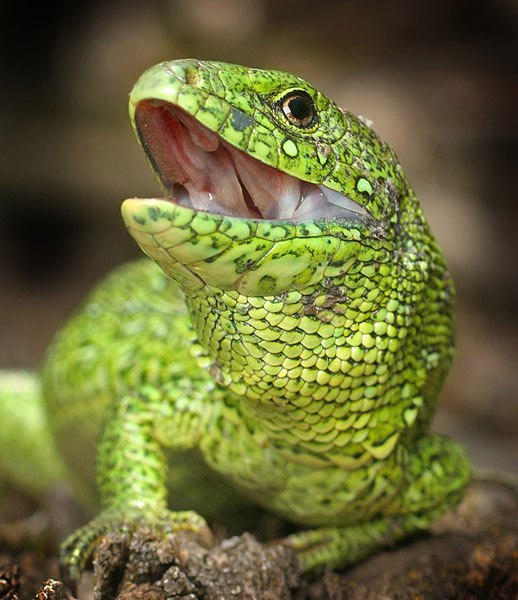

In [304]:
from IPython.display import Image
Image(filename='data/MobileNet-samples/1.PNG', width=300,height=200)

In [305]:
preprocessed_image = prepare_image('1.png')
predictions = mobile.predict(preprocessed_image)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


In [306]:
# 5 najbardziej prawdopodobnych klas z ImageNet
results = imagenet_utils.decode_predictions(predictions)
results

[[('n01693334', 'green_lizard', np.float32(0.63256013)),
  ('n01682714', 'American_chameleon', np.float32(0.15346605)),
  ('n01694178', 'African_chameleon', np.float32(0.0677811)),
  ('n01677366', 'common_iguana', np.float32(0.055007454)),
  ('n01689811', 'alligator_lizard', np.float32(0.032185752))]]

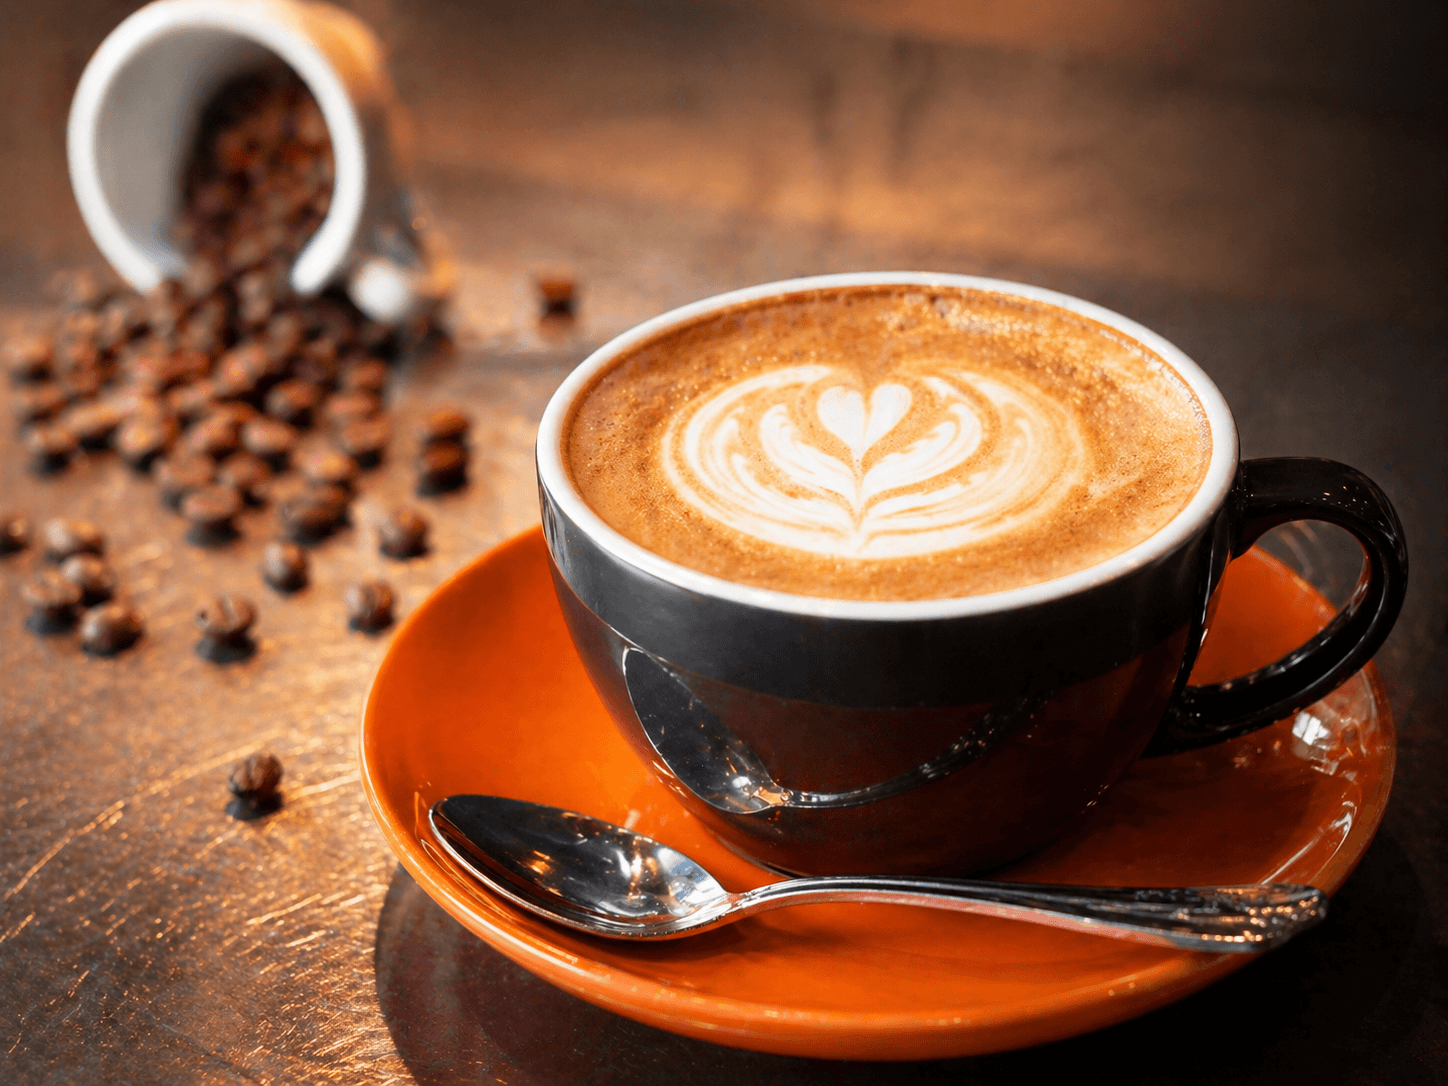

In [307]:
Image(filename='data/MobileNet-samples/2.png', width=300,height=200)

In [308]:
preprocessed_image = prepare_image('2.png')
predictions = mobile.predict(preprocessed_image)
results = imagenet_utils.decode_predictions(predictions)
results

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


[[('n07920052', 'espresso', np.float32(0.99996245)),
  ('n07930864', 'cup', np.float32(2.1293694e-05)),
  ('n04263257', 'soup_bowl', np.float32(5.4505904e-06)),
  ('n03063599', 'coffee_mug', np.float32(4.468806e-06)),
  ('n07892512', 'red_wine', np.float32(2.0374905e-06))]]

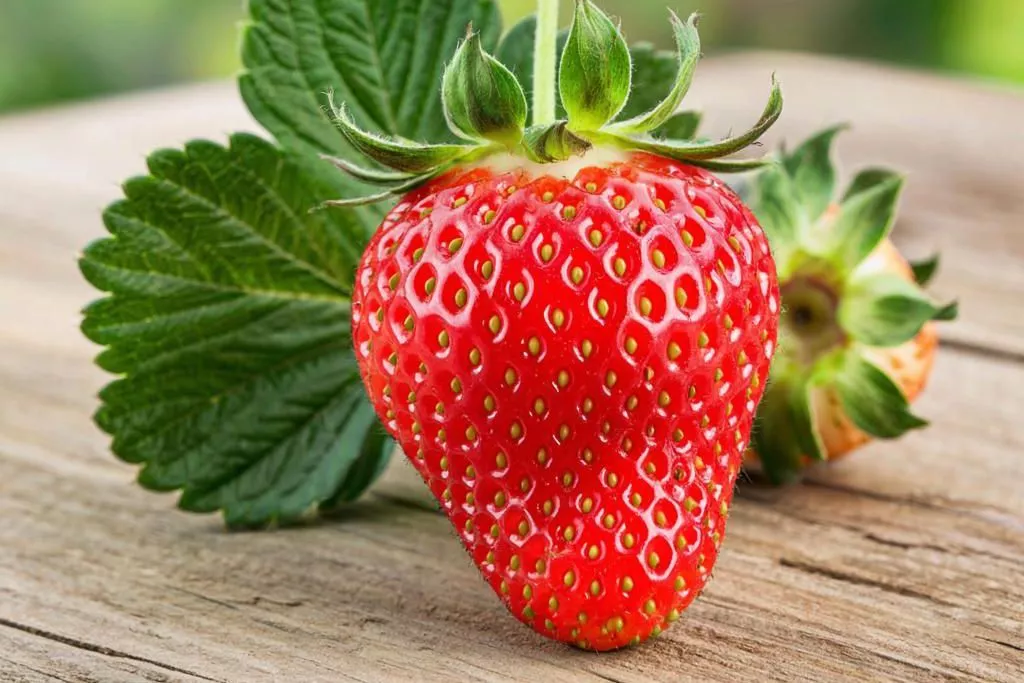

In [309]:
Image(filename='data/MobileNet-samples/3.png', width=300,height=200)

In [310]:
preprocessed_image = prepare_image('3.png')
predictions = mobile.predict(preprocessed_image)
results = imagenet_utils.decode_predictions(predictions)
results

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


[[('n07745940', 'strawberry', np.float32(0.9988072)),
  ('n07753275', 'pineapple', np.float32(0.0010628054)),
  ('n07747607', 'orange', np.float32(9.7856784e-05)),
  ('n07749582', 'lemon', np.float32(1.0773196e-05)),
  ('n07760859', 'custard_apple', np.float32(3.6942631e-06))]]

## Wideo 19: Przygotowanie obrazów do dostrajania MobileNet

Zbiór Sign Language Digits (wersja RGB z GitHub). W filmie pobierany ręcznie —
foldery `0`–`9` mają leżeć bezpośrednio w `data/Sign-Language-Digits-Dataset`.

In [311]:
if not os.path.isdir('data/Sign-Language-Digits-Dataset'):
    !git clone -q https://github.com/ardamavi/Sign-Language-Digits-Dataset.git data/sl-tmp
    shutil.move('data/sl-tmp/Dataset', 'data/Sign-Language-Digits-Dataset')
    shutil.rmtree('data/sl-tmp')

In [312]:
# Podział danych na foldery train, valid, test
os.chdir('data/Sign-Language-Digits-Dataset')
if os.path.isdir('train/0/') is False:
    os.mkdir('train')
    os.mkdir('valid')
    os.mkdir('test')

    for i in range(0, 10):
        shutil.move(f'{i}', 'train')
        os.mkdir(f'valid/{i}')
        os.mkdir(f'test/{i}')

        valid_samples = random.sample(os.listdir(f'train/{i}'), 30)
        for j in valid_samples:
            shutil.move(f'train/{i}/{j}', f'valid/{i}')

        test_samples = random.sample(os.listdir(f'train/{i}'), 5)
        for k in test_samples:
            shutil.move(f'train/{i}/{k}', f'test/{i}')
os.chdir('../..')

In [313]:
train_path = 'data/Sign-Language-Digits-Dataset/train'
valid_path = 'data/Sign-Language-Digits-Dataset/valid'
test_path = 'data/Sign-Language-Digits-Dataset/test'

In [314]:
train_batches = ImageDataGenerator(preprocessing_function=tf.keras.applications.mobilenet.preprocess_input).flow_from_directory(
    directory=train_path, target_size=(224,224), batch_size=10)
valid_batches = ImageDataGenerator(preprocessing_function=tf.keras.applications.mobilenet.preprocess_input).flow_from_directory(
    directory=valid_path, target_size=(224,224), batch_size=10)
test_batches = ImageDataGenerator(preprocessing_function=tf.keras.applications.mobilenet.preprocess_input).flow_from_directory(
    directory=test_path, target_size=(224,224), batch_size=10, shuffle=False)

Found 1712 images belonging to 10 classes.
Found 300 images belonging to 10 classes.
Found 50 images belonging to 10 classes.


## Wideo 20: Dostrajanie MobileNet na własnym zbiorze danych

In [315]:
mobile = tf.keras.applications.mobilenet.MobileNet()
mobile.summary()

Model: "mobilenet_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_17 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_bn (BatchNormalization)   │ (None, 112, 112, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_relu (ReLU)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1 (DepthwiseConv2D)     │ (None, 112, 112, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_bn                    │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_relu (ReLU)           │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1 (Conv2D)              │ (None, 112, 112, 64)   │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_bn                    │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_relu (ReLU)           │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pad_2 (ZeroPadding2D)      │ (None, 113, 113, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2 (DepthwiseConv2D)     │ (None, 56, 56, 64)     │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_bn                    │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_relu (ReLU)           │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2 (Conv2D)              │ (None, 56, 56, 128)    │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_relu (ReLU)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3 (DepthwiseConv2D)     │ (None, 56, 56, 128)    │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_relu (ReLU)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3 (Conv2D)              │ (None, 56, 56, 128)    │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 4,253,864 (16.23 MB)

 Trainable params: 4,231,976 (16.14 MB)

 Non-trainable params: 21,888 (85.50 KB)

In [316]:
# Wyjście z piątej od końca warstwy (global_average_pooling)
x = mobile.layers[-5].output

In [317]:
x = tf.keras.layers.Reshape(target_shape=(1024,))(x)
output = Dense(units=10, activation='softmax')(x)

In [318]:
# Nowy model (Functional API)
model = Model(inputs=mobile.input, outputs=output)

In [319]:
# Trenujemy tylko ostatnie 22 warstwy
for layer in model.layers[:-22]:
    layer.trainable = False

In [320]:
model.summary()

Model: "functional_94"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_17 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_bn (BatchNormalization)   │ (None, 112, 112, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_relu (ReLU)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1 (DepthwiseConv2D)     │ (None, 112, 112, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_bn                    │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_relu (ReLU)           │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1 (Conv2D)              │ (None, 112, 112, 64)   │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_bn                    │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_relu (ReLU)           │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pad_2 (ZeroPadding2D)      │ (None, 113, 113, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2 (DepthwiseConv2D)     │ (None, 56, 56, 64)     │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_bn                    │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_relu (ReLU)           │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2 (Conv2D)              │ (None, 56, 56, 128)    │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_relu (ReLU)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3 (DepthwiseConv2D)     │ (None, 56, 56, 128)    │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_relu (ReLU)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3 (Conv2D)              │ (None, 56, 56, 128)    │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 3,239,114 (12.36 MB)

 Trainable params: 1,872,906 (7.14 MB)

 Non-trainable params: 1,366,208 (5.21 MB)

# **Train the model**

In [321]:
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

In [322]:
model.fit(x=train_batches,
            steps_per_epoch=len(train_batches),
            validation_data=valid_batches,
            validation_steps=len(valid_batches),
            epochs=10,
            verbose=2
)

Epoch 1/10
172/172 - 17s - 99ms/step - accuracy: 0.8061 - loss: 0.6315 - val_accuracy: 0.8733 - val_loss: 0.4078
Epoch 2/10
172/172 - 4s - 22ms/step - accuracy: 0.9831 - loss: 0.1058 - val_accuracy: 0.9800 - val_loss: 0.1258
Epoch 3/10
172/172 - 4s - 22ms/step - accuracy: 0.9942 - loss: 0.0543 - val_accuracy: 0.9800 - val_loss: 0.1001
Epoch 4/10
172/172 - 4s - 22ms/step - accuracy: 0.9959 - loss: 0.0368 - val_accuracy: 0.9800 - val_loss: 0.0820
Epoch 5/10
172/172 - 4s - 22ms/step - accuracy: 0.9988 - loss: 0.0198 - val_accuracy: 0.9833 - val_loss: 0.0837
Epoch 6/10
172/172 - 4s - 22ms/step - accuracy: 0.9965 - loss: 0.0207 - val_accuracy: 0.9733 - val_loss: 0.0977
Epoch 7/10
172/172 - 4s - 21ms/step - accuracy: 0.9982 - loss: 0.0188 - val_accuracy: 0.9700 - val_loss: 0.0948
Epoch 8/10
172/172 - 4s - 23ms/step - accuracy: 0.9988 - loss: 0.0115 - val_accuracy: 0.9833 - val_loss: 0.0876
Epoch 9/10
172/172 - 4s - 21ms/step - accuracy: 0.9994 - loss: 0.0117 - val_accuracy: 0.9900 - val_loss

# **Predict sign language digits**

In [323]:
test_labels = test_batches.classes

In [324]:
predictions = model.predict(x=test_batches, steps=len(test_batches), verbose=0)

In [325]:
cm = confusion_matrix(y_true=test_labels, y_pred=predictions.argmax(axis=1))

In [326]:
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    Funkcja wypisuje i rysuje macierz pomyłek.
    Normalizację można włączyć, ustawiając `normalize=True`.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
            horizontalalignment="center",
            color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

In [327]:
test_batches.class_indices

{'0': 0,
 '1': 1,
 '2': 2,
 '3': 3,
 '4': 4,
 '5': 5,
 '6': 6,
 '7': 7,
 '8': 8,
 '9': 9}

Confusion matrix, without normalization
[[5 0 0 0 0 0 0 0 0 0]
 [0 5 0 0 0 0 0 0 0 0]
 [0 0 5 0 0 0 0 0 0 0]
 [0 0 0 4 0 0 0 1 0 0]
 [0 0 0 0 5 0 0 0 0 0]
 [0 0 0 0 0 5 0 0 0 0]
 [0 0 0 0 0 0 5 0 0 0]
 [0 0 0 0 0 0 0 5 0 0]
 [0 0 0 0 0 0 0 0 5 0]
 [0 0 0 0 0 0 0 0 0 5]]


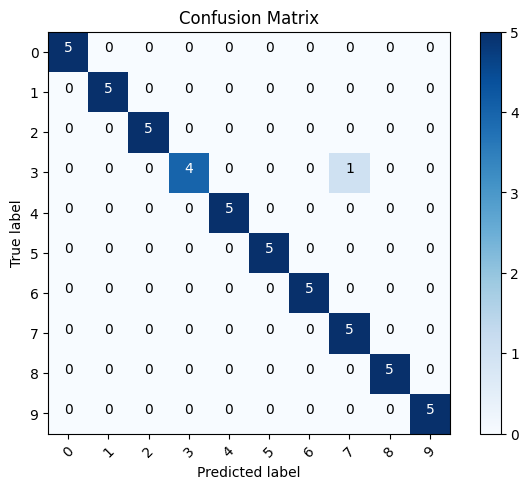

In [328]:
cm_plot_labels = ['0','1','2','3','4','5','6','7','8','9']
plot_confusion_matrix(cm=cm, classes=cm_plot_labels, title='Confusion Matrix')

## Wideo 21: Podsumowanie kursu

Wideo podsumowujące — bez kodu.